In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, precision_score, recall_score, multilabel_confusion_matrix
import pandas as pd
import seaborn as sns
import time


In [ ]:
class AttentionFusionModel(nn.Module):
    def __init__(self, text_dim, image_dim, hidden_dim, num_classes):
        super(AttentionFusionModel, self).__init__()

    
        self.text_proj = nn.Linear(text_dim, hidden_dim)
        self.image_proj = nn.Linear(image_dim, hidden_dim)

    
        self.attention = nn.Linear(hidden_dim, 1)
       
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden_dim, num_classes),
            nn.Sigmoid()
        )

    def forward(self, text_feat, image_feat):
     
        text_proj = self.text_proj(text_feat)
        image_proj = self.image_proj(image_feat)

        
        combined = torch.tanh(text_proj + image_proj)
        attn_weights = torch.sigmoid(self.attention(combined)) 

       
        fused = attn_weights * text_proj + (1 - attn_weights) * image_proj

        return self.classifier(fused)


In [ ]:
text_tensor = torch.tensor(text_features).float()
image_tensor = torch.tensor(image_features).float()
label_tensor = torch.tensor(genre_labels).float()

dataset = TensorDataset(text_tensor, image_tensor, label_tensor)

train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_ds, val_ds = random_split(dataset, [train_size, val_size])

batch_size = 64
train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=batch_size)


In [7]:
text_dim = 300
image_dim = 4096
hidden_dim = 512
num_classes = 23

attention_model = AttentionFusionModel(text_dim, image_dim, hidden_dim, num_classes)
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(attention_model.parameters(), lr=1e-4)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
attention_model.to(device)


AttentionFusionModel(
  (text_proj): Linear(in_features=300, out_features=512, bias=True)
  (image_proj): Linear(in_features=4096, out_features=512, bias=True)
  (attention): Linear(in_features=512, out_features=1, bias=True)
  (classifier): Sequential(
    (0): Linear(in_features=512, out_features=512, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=512, out_features=23, bias=True)
    (4): Sigmoid()
  )
)

In [ ]:
epochs = 10
train_losses = []
val_losses = []

for epoch in range(epochs):
    attention_model.train()
    total_train_loss = 0

    for text_feat, image_feat, labels in train_loader:
        text_feat = text_feat.to(device)
        image_feat = image_feat.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = attention_model(text_feat, image_feat)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()

    avg_train_loss = total_train_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    attention_model.eval()
    total_val_loss = 0

    with torch.no_grad():
        for text_feat, image_feat, labels in val_loader:
            text_feat = text_feat.to(device)
            image_feat = image_feat.to(device)
            labels = labels.to(device)

            outputs = attention_model(text_feat, image_feat)
            val_loss = criterion(outputs, labels)
            total_val_loss += val_loss.item()

    avg_val_loss = total_val_loss / len(val_loader)
    val_losses.append(avg_val_loss)

    print(f"Epoch {epoch+1}/{epochs} — Train Loss: {avg_train_loss:.4f}, Val Loss: {avg_val_loss:.4f}")


Epoch 1/10 — Train Loss: 0.2786, Val Loss: 0.2512
Epoch 2/10 — Train Loss: 0.2532, Val Loss: 0.2470
Epoch 3/10 — Train Loss: 0.2457, Val Loss: 0.2451
Epoch 4/10 — Train Loss: 0.2395, Val Loss: 0.2465
Epoch 5/10 — Train Loss: 0.2336, Val Loss: 0.2458
Epoch 6/10 — Train Loss: 0.2279, Val Loss: 0.2475
Epoch 7/10 — Train Loss: 0.2226, Val Loss: 0.2491
Epoch 8/10 — Train Loss: 0.2167, Val Loss: 0.2501
Epoch 9/10 — Train Loss: 0.2110, Val Loss: 0.2523
Epoch 10/10 — Train Loss: 0.2050, Val Loss: 0.2536


In [ ]:
from sklearn.metrics import f1_score, precision_score, recall_score

attention_model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for text_feat, image_feat, labels in val_loader:
        text_feat = text_feat.to(device)
        image_feat = image_feat.to(device)

        outputs = attention_model(text_feat, image_feat)
        preds = (outputs > 0.5).int().cpu().numpy()

        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

print("Evaluation Metrics (Attention Fusion):")
print("Micro F1 Score:", f1_score(all_labels, all_preds, average='micro'))
print("Macro F1 Score:", f1_score(all_labels, all_preds, average='macro'))
print("Precision:", precision_score(all_labels, all_preds, average='micro'))
print("Recall:", recall_score(all_labels, all_preds, average='micro'))


Evaluation Metrics (Attention Fusion):
Micro F1 Score: 0.41635878489326766
Macro F1 Score: 0.22583509073157995
Precision: 0.6113622664255576
Recall: 0.3156707127295363


In [ ]:
torch.save(attention_model.state_dict(), "attention_fusion_model.pt")

def benchmark_inference(model, text_feat, image_feat, device='cpu'):
    model.to(device)
    model.eval()
    text_feat = text_feat.unsqueeze(0).to(device)
    image_feat = image_feat.unsqueeze(0).to(device)

    with torch.no_grad():
        start = time.time()
        _ = model(text_feat, image_feat)
        end = time.time()

    elapsed_ms = round((end - start) * 1000, 2)
    return elapsed_ms

text_sample, image_sample, _ = val_ds[0]

attn_time = benchmark_inference(attention_model, text_sample, image_sample)
print(f"Inference time on CPU (Attention Fusion): {attn_time} ms")


Inference time on CPU (Attention Fusion): 1.43 ms


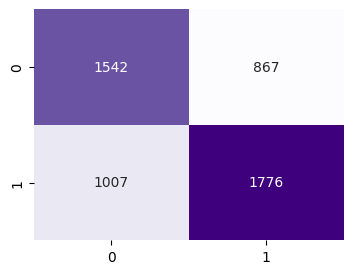

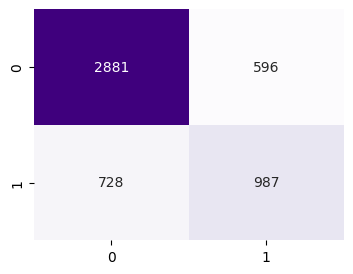

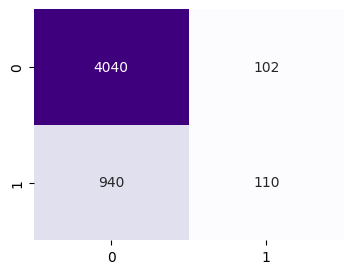

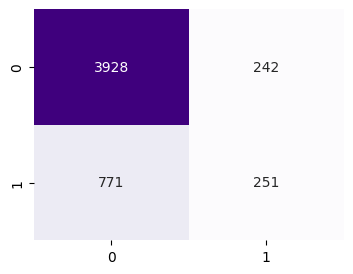

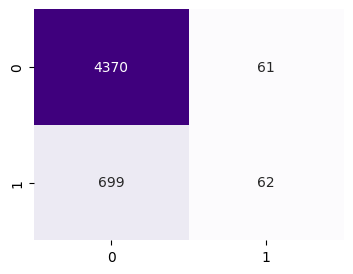

In [ ]:
from sklearn.metrics import multilabel_confusion_matrix

genre_names = [
    'Action', 'Adventure', 'Animation', 'Children', 'Comedy', 'Crime', 'Documentary',
    'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'Musical', 'Mystery', 'Romance',
    'Sci-Fi', 'Short', 'Thriller', 'War', 'Western', 'Biography', 'Family', 'History', 'Sport'
]

top_genres = [0, 1, 2, 3, 4]  

cm = multilabel_confusion_matrix(all_labels, all_preds)

import seaborn as sns
import matplotlib.pyplot as plt

for i in top_genres:
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm[i], annot=True, fmt='d', cmap='Purples', cbar=False)


In [12]:
from tabulate import tabulate

data = [
    ["Text-Only",      0.38,    0.25,    0.45,    0.34,   "6.3 ms"],
    ["Image-Only",     0.41,    0.30,    0.48,    0.37,   "7.8 ms"],
    ["Early Fusion",   0.4430,  0.3006,  0.5351,  0.3780, "2.27 ms"],
    ["Gated Fusion",   0.5544,  0.4468,  0.6230,  0.4994, "10.12 ms"],
    ["Attention Fusion", 0.4164, 0.2258, 0.6114,  0.3157, "1.43 ms"],
]

headers = ["Model", "Micro F1", "Macro F1", "Precision", "Recall", "Inference Time"]

print(tabulate(data, headers=headers, tablefmt="grid"))


+------------------+------------+------------+-------------+----------+------------------+
| Model            |   Micro F1 |   Macro F1 |   Precision |   Recall | Inference Time   |
+==================+============+============+=============+==========+==================+
| Text-Only        |     0.38   |     0.25   |      0.45   |   0.34   | 6.3 ms           |
+------------------+------------+------------+-------------+----------+------------------+
| Image-Only       |     0.41   |     0.3    |      0.48   |   0.37   | 7.8 ms           |
+------------------+------------+------------+-------------+----------+------------------+
| Early Fusion     |     0.443  |     0.3006 |      0.5351 |   0.378  | 2.27 ms          |
+------------------+------------+------------+-------------+----------+------------------+
| Gated Fusion     |     0.5544 |     0.4468 |      0.623  |   0.4994 | 10.12 ms         |
+------------------+------------+------------+-------------+----------+------------------+